# Days to recovered discharge in Nara

A district nutrition coordinator can use the estimated elapsed duration to plan how long cases that recover may remain on the caseload. The estimate includes programme time for cases that transfer to inpatient care. The coordinator needs separate estimates for other discharge outcomes and for the number of outpatient visits.

Run the notebook with the `summative/.venv` Python kernel after running `uv sync --locked` in `summative/`. Save the original Zenodo CSV in `summative/data/` and run the cohort audit from the README to verify the source checksum.

In [1]:
from pathlib import Path

import pandas as pd
from sklearn.model_selection import train_test_split

data_dir = Path("data") if Path("pyproject.toml").is_file() else Path("../data")
source = pd.read_csv(data_dir / "Mali_Cohort_Study.csv", na_values=["."])

assert source["AnonID"].notna().all() and source["AnonID"].is_unique
source.shape

(27800, 58)

## Select the modeling cohort

Use recovered health-centre cases with a positive recorded duration. Keep only admission fields as candidate predictors. Site is constant after filtering. Record ID is reserved for checking the splits and the inpatient transfer flag is reserved for evaluating errors by subgroup.

All 18 eligible records with oedema lack weight-for-height z-score. Require the seven shared inputs for the main split so that cases with oedema remain represented. Compare seven and eight inputs on the same z-score-complete rows within each split. Confirm z-score availability in the coordinator's workflow before finalizing the input fields.

In [2]:
numeric_features = ["adm_age", "adm_kg", "adm_cm", "adm_muac"]
categorical_features = ["adm_sex", "adm_oedema_YN", "adm_referral"]
shared_features = numeric_features + categorical_features
z_score = "adm_whz06"
target = "recovered_los"

eligible = source.loc[
    source["adm_site"].eq("Health Center")
    & source["cured"].eq(1)
    & source[target].gt(0)
]
cohort = (
    eligible[["AnonID", *shared_features, z_score, target, "transfer_inpatient"]]
    .dropna(subset=shared_features)
    .set_index("AnonID")
    .sort_index()
)
print(f"{len(eligible):,} eligible records, {len(cohort):,} with the shared inputs")
print(f"{cohort[z_score].notna().sum():,} also have a z-score")
print(f"Recorded duration ranges from {cohort[target].min():g} to {cohort[target].max():g} days")

20,484 eligible records, 20,057 with the shared inputs
20,002 also have a z-score
Recorded duration ranges from 10 to 112 days


## Reserve test and retraining rows

The CSV has no admission date, so these are random splits of historical records. Reserve 20% for the shared test set and 10% for the retraining demonstration. The demo batch remains outside preprocessing, tuning, and model selection. Preserve the rare oedema category in each split by stratifying on the admission flag.

In [3]:
seed = 42
train_and_demo, test = train_test_split(
    cohort, test_size=0.20, random_state=seed, stratify=cohort["adm_oedema_YN"]
)
train, retraining_batch = train_test_split(
    train_and_demo,
    test_size=0.125,
    random_state=seed,
    stratify=train_and_demo["adm_oedema_YN"],
)

splits = {"train": train, "test": test, "retraining": retraining_batch}
split_ids = pd.Index([record_id for rows in splits.values() for record_id in rows.index])
assert split_ids.is_unique and len(split_ids) == len(cohort)

pd.DataFrame({
    name: {
        "Rows": len(rows),
        "With z-score": rows[z_score].notna().sum(),
        "Oedema cases": rows["adm_oedema_YN"].eq(1).sum(),
    }
    for name, rows in splits.items()
}).T

,Rows,With z-score,Oedema cases
train,14039,14002,10
test,4012,4001,3
retraining,2006,1999,2


## Explore recovery duration

Each bar groups training cases into a seven-day interval. The held-out test and retraining groups stay separate from this exploration.

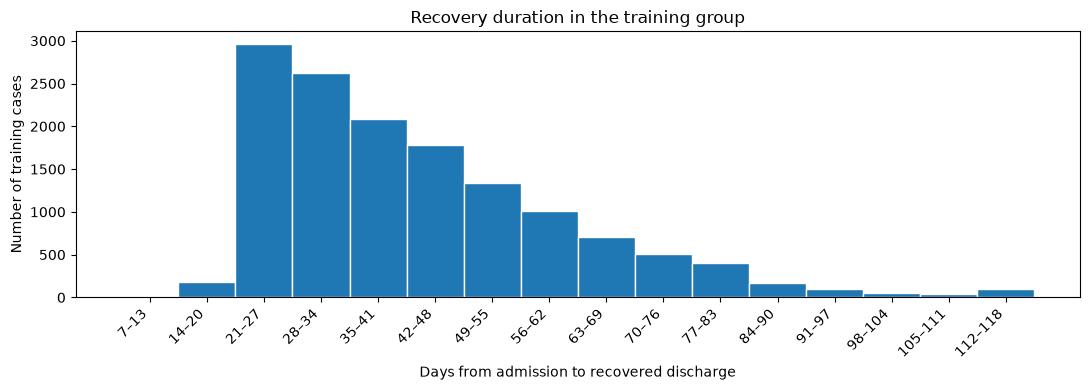

In [5]:
import matplotlib.pyplot as plt

week_starts = list(range(7, 113, 7))
week_labels = [f"{day}–{day + 6}" for day in week_starts]

fig, ax = plt.subplots(figsize=(11, 4))
ax.hist(train[target], bins=[*week_starts, 119], edgecolor="white")
ax.set_xticks([day + 3.5 for day in week_starts], week_labels, rotation=45, ha="right")
ax.set(xlabel="Days from admission to recovered discharge",
       ylabel="Number of training cases",
       title="Recovery duration in the training group")
fig.tight_layout()
plt.show()

The tallest bar covers 21–27 days and contains 2,962 training cases. The median is 35 days, and 1,365 cases (about 10%) took at least 70 days. I'll use the training mean as a baseline for the MSE comparison and also report mean absolute error in days so we can see the typical size of a prediction error.

## Compare numeric inputs

The heatmap uses training rows and computes each correlation from cases with both values present. WHZ stands for weight-for-height z-score.

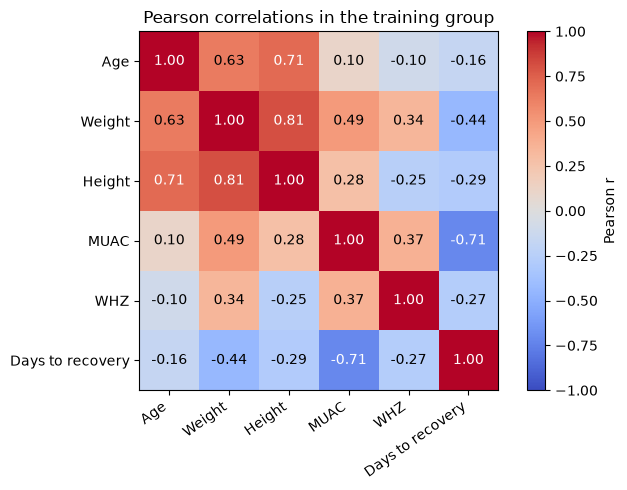

In [6]:
from matplotlib.colors import TwoSlopeNorm

# Pearson correlation describes linear relationships between numeric columns.
numeric_columns = [*numeric_features, z_score, target]
correlations = train[numeric_columns].corr()
labels = ["Age", "Weight", "Height", "MUAC", "WHZ", "Days to recovery"]

fig, ax = plt.subplots(figsize=(7, 5))
heatmap = ax.imshow(
    correlations, cmap="coolwarm", norm=TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1)
)
ax.set_xticks(range(len(labels)), labels, rotation=35, ha="right")
ax.set_yticks(range(len(labels)), labels)
ax.set_title("Pearson correlations in the training group")

for row, values in enumerate(correlations.to_numpy()):
    for column, value in enumerate(values):
        color = "white" if abs(value) >= 0.65 else "black"
        ax.text(column, row, f"{value:.2f}", ha="center", va="center", color=color)

fig.colorbar(heatmap, ax=ax, label="Pearson r")
fig.tight_layout()
plt.show()

MUAC has the strongest linear relationship with duration (r = -0.71). Smaller admission MUAC tends to go with longer stays, so I'll use it for the one-feature scatter plots. The heatmap shows one input at a time against the target, so I'll test whether WHZ adds value by comparing models on the same records with and without it.

## Compare admission categories

Counts and median durations show how the training cases differ by sex, oedema status, and referral source.

In [7]:
category_summary = pd.concat(
    {
        feature: train.groupby(feature)[target].agg(
            cases="size", median_days="median"
        )
        for feature in categorical_features
    },
    names=["Admission field", "Category"],
)
category_summary.rename(
    columns={"cases": "Training cases", "median_days": "Median recovery days"}
)

Training cases  Median recovery days
Admission field Category                                          
adm_sex         Female                  7494                  35.0
                Male                    6545                  35.0
adm_oedema_YN   0                      14029                  35.0
                1                         10                  39.5
adm_referral    CHW - Relais            5625                  35.0
                Family MUAC             5415                  35.0
                Other                    417                  35.0
                Walk-in                 2582                  35.0

Only 10 training cases have oedema, so their median can shift with just a few records. I’ll keep oedema as a candidate and avoid drawing strong conclusions about that group. I’ll one-hot encode referral source so the model can use each category without imposing an order.

## Examine admission MUAC before and after fitting

MUAC is mid-upper arm circumference, measured in millimetres. Both panels show the same training records. Darker areas show where recorded values overlap.

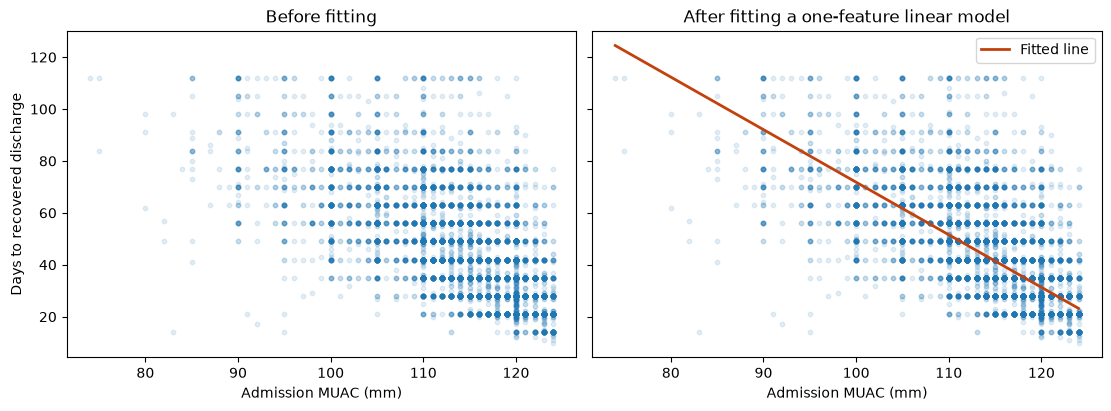

In [8]:
from sklearn.linear_model import LinearRegression

muac = train[["adm_muac"]]
durations = train[target]
muac_model = LinearRegression().fit(muac, durations)
line_inputs = muac.drop_duplicates().sort_values("adm_muac")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, layout="constrained")
for ax in axes:
    ax.scatter(muac["adm_muac"], durations, s=10, alpha=0.12)
    ax.set_xlabel("Admission MUAC (mm)")

axes[0].set(title="Before fitting", ylabel="Days to recovered discharge")
axes[1].set_title("After fitting a one-feature linear model")
axes[1].plot(
    line_inputs["adm_muac"], muac_model.predict(line_inputs), color="#c2410c",
    linewidth=2, label="Fitted line",
)
axes[1].legend()
plt.show()

The fitted line slopes downward, in line with the negative correlation in the heatmap. Cases with the same admission MUAC still vary widely in recovery duration, so I'll check whether the multivariate models improve predictions on the held-out test rows.

## Set a mean-duration baseline

The baseline predicts the same number of days for every case. That number is the training mean, which minimizes squared error among constant predictions. We'll score this baseline on the same held-out rows as the four models when their settings are final.

In [9]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

baseline = DummyRegressor(strategy="mean")
baseline.fit(train[shared_features], train[target])
baseline_train_predictions = baseline.predict(train[shared_features])

pd.Series({
    "Constant prediction (days)": baseline.constant_.item(),
    "Training MSE (days squared)": mean_squared_error(train[target], baseline_train_predictions),
    "Training MAE (days)": mean_absolute_error(train[target], baseline_train_predictions),
}).round(2)

Constant prediction (days)      40.19
Training MSE (days squared)    342.57
Training MAE (days)             14.67
dtype: float64

## Prepare numeric and categorical inputs

Standardize each numeric column using its training mean and standard deviation. Encode categories as separate indicator columns. Every fit, including a validation fit, will build its own preprocessor so those statistics and categories come from the rows used to fit that model.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def make_preprocessor(numeric_columns, categorical_columns):
    return ColumnTransformer(
        [
            ("numeric", StandardScaler(), numeric_columns),
            ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
        ],
        verbose_feature_names_out=False,
    )


preview_preprocessor = make_preprocessor(numeric_features, categorical_features)
encoded_train = preview_preprocessor.fit_transform(train[shared_features])
print(f"{len(shared_features)} raw inputs become {encoded_train.shape[1]} model columns")
pd.DataFrame(
    encoded_train[:5],
    columns=preview_preprocessor.get_feature_names_out(),
).round(2)

7 raw inputs become 12 model columns


,adm_age,adm_kg,adm_cm,adm_muac,adm_sex_Female,adm_sex_Male,adm_oedema_YN_0,adm_oedema_YN_1,adm_referral_CHW - Relais,adm_referral_Family MUAC,adm_referral_Other,adm_referral_Walk-in
0,-1.06,0.58,-1.39,-0.86,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
1,1.09,2.07,1.10,1.29,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0
2,-0.39,0.41,0.06,0.98,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
3,-0.79,0.25,-0.17,0.67,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
4,0.55,-1.41,-0.93,-1.02,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


## Check the contribution of WHZ and oedema

Set aside 20% of the training group for validation. For each feature comparison, fit two linear models using the same rows, changing only the feature under review. The WHZ comparison uses rows with a recorded z-score. The oedema comparison uses all rows in the training-side split, including those with missing WHZ.

In [11]:
from sklearn.pipeline import Pipeline

fit_rows, validation_rows = train_test_split(
    train, test_size=0.20, random_state=seed, stratify=train["adm_oedema_YN"]
)


def validation_mse(fitting, validation, numeric_columns, categorical_columns):
    inputs = numeric_columns + categorical_columns
    model = Pipeline([
        ("preprocessing", make_preprocessor(numeric_columns, categorical_columns)),
        ("regression", LinearRegression()),
    ])
    model.fit(fitting[inputs], fitting[target])
    return mean_squared_error(validation[target], model.predict(validation[inputs]))


whz_fit = fit_rows.dropna(subset=[z_score])
whz_validation = validation_rows.dropna(subset=[z_score])
without_oedema = [field for field in categorical_features if field != "adm_oedema_YN"]

feature_checks = pd.DataFrame.from_dict({
    "WHZ": {
        "Validation rows": len(whz_validation),
        "MSE without": validation_mse(
            whz_fit, whz_validation, numeric_features, without_oedema
        ),
        "MSE with": validation_mse(
            whz_fit, whz_validation, [*numeric_features, z_score], without_oedema
        ),
    },
    "Oedema": {
        "Validation rows": len(validation_rows),
        "MSE without": validation_mse(
            fit_rows, validation_rows, numeric_features, without_oedema
        ),
        "MSE with": validation_mse(
            fit_rows, validation_rows, numeric_features, categorical_features
        ),
    },
}, orient="index")
feature_checks["MSE improvement"] = feature_checks["MSE without"] - feature_checks["MSE with"]
feature_checks.round(3)

,Validation rows,MSE without,MSE with,MSE improvement
WHZ,2800,151.254,151.212,0.042
Oedema,2808,151.945,151.480,0.465


Adding WHZ reduced validation MSE by only 0.042 days squared on the matched rows. I’ll leave it out of the main model comparison so cases without a recorded z-score can still be included.

Adding oedema reduced validation MSE by 0.465 days squared. Only two validation cases had oedema, so this split gives little evidence about performance for that group.

## Tune gradient descent on training-side validation

Compare three constant learning rates, three L2 regularization strengths, and checkpoints after 10, 30, and 80 passes through the fitting rows. A learning rate controls the size of each update. L2 regularization discourages large coefficients. Each trial sees the same row order in each epoch so the settings can be compared directly.

In [12]:
from itertools import product

import numpy as np
from sklearn.linear_model import SGDRegressor

sgd_preprocessor = make_preprocessor(numeric_features, categorical_features)
fit_inputs = sgd_preprocessor.fit_transform(fit_rows[shared_features])
validation_inputs = sgd_preprocessor.transform(validation_rows[shared_features])
fit_days = fit_rows[target].to_numpy()

epoch_checkpoints = (10, 30, 80)
sgd_trials = []
for rate, alpha in product((0.001, 0.005, 0.01), (0.0001, 0.01, 0.1)):
    estimator = SGDRegressor(
        learning_rate="constant", eta0=rate, penalty="l2", alpha=alpha,
        shuffle=False, random_state=seed,
    )
    rng = np.random.default_rng(seed)
    for epoch in range(1, max(epoch_checkpoints) + 1):
        order = rng.permutation(len(fit_days))
        estimator.partial_fit(fit_inputs[order], fit_days[order])
        if epoch in epoch_checkpoints:
            prediction = estimator.predict(validation_inputs)
            sgd_trials.append({
                "learning_rate": rate,
                "alpha": alpha,
                "epochs": epoch,
                "validation_mse": mean_squared_error(validation_rows[target], prediction),
            })

sgd_results = pd.DataFrame(sgd_trials).sort_values(
    ["validation_mse", "epochs"], ignore_index=True
)
best_sgd = sgd_results.iloc[0]
sgd_results.round({"validation_mse": 3})

,learning_rate,alpha,epochs,validation_mse
0,0.005,0.0001,80,151.926
1,0.005,0.1000,10,151.957
2,0.005,0.0100,10,152.237
3,0.010,0.1000,10,152.265
4,0.001,0.0100,10,152.285
5,0.001,0.0001,80,152.304
6,0.005,0.0100,80,152.407
7,0.001,0.0100,80,152.435
8,0.001,0.0100,30,152.455
9,0.005,0.0001,10,152.463


The lowest validation MSE was 151.926 days squared at a learning rate of 0.005, L2 alpha of 0.0001, and 80 epochs. At that rate and alpha, MSE was 152.463 after 10 epochs, rose at 30, then fell at 80. More passes did not consistently lower the loss.

At 80 epochs and alpha 0.0001, the middle learning rate beat both the lower and higher rates. At that rate and 80 epochs, stronger regularization raised the error, though alpha 0.1 after just 10 epochs came close to the best score. These settings are now fixed for the held-out comparison.